# 3.4 How do I make my custom QRenderer?

This notebook walks through a complete, working example of a user-defined renderer:
`QSkeletonRenderer`. By the end you will understand:

1. How Qiskit Metal's renderer architecture works and where to plug in a new one
2. The three required methods every renderer must implement
3. How to add renderer-specific columns to the `QGeometry` tables
4. How to read, filter, and act on `QGeometry` data from inside a renderer

**The skeleton renderer is already written** — it lives at
`docs/tut/resources/skeleton_renderer.py`. You only need to register it
in `renderers_to_load` before creating a `QDesign`; the cell below does that at
runtime, so the notebook runs on any install. To make a renderer available in
every session, add the same entry to `config.py` instead.

> 💡 **Using this tutorial without the Qt GUI**
> 
> This tutorial uses the desktop `MetalGUI`. To follow along on Colab, Binder, JupyterHub, or any environment where Qt isn't available, **replace any `gui.rebuild()` / `gui.screenshot()` call with `qm.view(design)`** — it renders the design to a matplotlib `Figure` you can display inline or save with `fig.savefig(...)`.
> 
> See [1.1 Quick start](https://qiskit-community.github.io/qiskit-metal/tut/1-Overview/1.1-Quick-start.html) for a complete runnable walkthrough and [`docs/headless-usage.rst`](https://qiskit-community.github.io/qiskit-metal/headless-usage.html) for the full reference.

Pre-load all the Qiskit Metal libraries that are needed for the rest of this notebook.

In [1]:
import qiskit_metal as metal
from qiskit_metal import designs, draw
from qiskit_metal import MetalGUI, Dict, Headings

from qiskit_metal.qlibrary.qubits.transmon_pocket import TransmonPocket
from qiskit_metal.qlibrary.qubits.transmon_cross import TransmonCross

from qiskit_metal.renderers.renderer_gds.gds_renderer import QGDSRenderer

## Integrating the user-defined renderer with the rest of Qiskit Metal
### Architectural insights
This section will give you the architectural overview of how Qiskit Metal manages renderers, and how you can add your own.

We will refer to your custom renderer as the `skeleton` renderer, since we will not code tool-specific methods/classes, but only worry about how to bootstrap one without functionality.

Note that all renderers (existing `gds`, `hfss` and `q3d` as well as the newly created `skeleton`) have to be identified in the config.py file.  Therefore, your renderer has to be added to `config.renderers_to_load`, either at runtime (as below) or in the `qiskit_metal/config.py` file.

The following image describes how the QRenderer (superclass of all renderers) interacts with the rest of Qiskit Metal.  The key take-away is that creating a QDesign class object initiates all the QRenderer subclass objects as well.  Specifically, the `QDesign.__init__()` method reads the `renderers_to_load` dictionary from the config.py file, which enumerates which QRenderers subclasses need to be instantiated.  After instantiating the renderer objects, the `QDesign.__init__()` registers them in the `QDesign._renderers` dictionary for later reference.

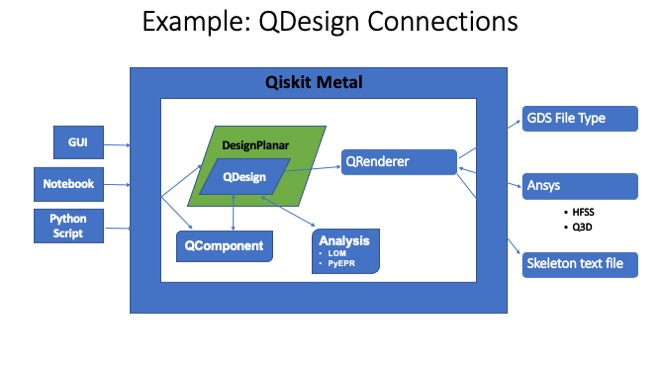

### QRenderer inheritance and subclass management

Presently, the config.py file references three QRenderers subclasses, which handle the `gds`, `hfss` and `q3d` interfaces.  Explicitly, QGDSRenderer is a subclass of QRenderer.  Both QHFSSRenderer and QQ3DRenderer subclass from QAnsysRenderer.  The class QAnsysRenderer is a subclass of QRenderer.

The `renderers_to_load` dictionary in the config.py file needs to be updated to inform Qiskit Metal about the new renderer `skeleton` you are going to create.  `renderers_to_load` stores the explicit path and class name so that Qiskit Metal will load to memory by default only those specified renderers. This happens during the `QDesign.__init__()`.

For this notebook, we created a sample class named QSkeletonRender in `docs/tut/resources/skeleton_renderer`.  This class is your skeleton to develop a new QRenderer subclass.  Feel free to edit the class content at will. If you change the path to the file, please reflect that in the remainder of this notebook.  Presently, you can find the production QRenderers subclasses in the package directory `qiskit_metal.renderers`.

### Register the skeleton renderer

A renderer is registered by an entry in `config.renderers_to_load`, the dictionary
that `QDesign.__init__` reads to instantiate its renderers. The cell below adds the
skeleton renderer at runtime; it must run before the design is created. The module
path is relative to `sys.path`, so the cell first makes `docs/tut/resources`
importable (this notebook lives in `docs/tut/3-Renderers`).

To register a renderer permanently, add the same entry to `renderers_to_load` in
`src/qiskit_metal/config.py` (with `path_name` a module importable from anywhere,
e.g. one inside your own package) and restart the kernel.

> **Why `renderers_to_load`?** Qiskit Metal reads it during `QDesign.__init__`
> to instantiate and register all renderers automatically, so users never have to
> import or instantiate a renderer manually.

In [2]:
import os
import sys

from qiskit_metal import config

sys.path.insert(0, os.path.abspath(os.path.join("..", "resources")))
config.renderers_to_load["skeleton"] = Dict(
    path_name="skeleton_renderer", class_name="QSkeletonRenderer"
)

### The skeleton renderer source

Open [`docs/tut/resources/skeleton_renderer.py`](../resources/skeleton_renderer.py)
to read the full implementation. The three methods every renderer must provide are
already implemented there:

```python
def _initiate_renderer(self):
    """Called when the renderer is registered. Return True on success."""
    return True

def _close_renderer(self):
    """Called on cleanup / disconnect. Return True on success."""
    return True

def render_design(self):
    """The main export entry point called by the GUI toolbar and scripts."""
    self.write_qgeometry_table_names_to_file(
        file_name=self.options.file_geometry_tables,
        highlight_qcomponents=[],
    )
```

For your own renderer, replace the body of `render_design` with calls to
your target tool's API (e.g. open a file, call a COM interface, write a mesh).

### Confirm QDesign is able to load your renderer
Create a QDesign instance.

In [3]:
design = designs.DesignPlanar()

If the registration cell ran before it, the previous command instantiated and registered the `skeleton` renderer.  Verify that by inspecting the renderers dictionary property of the QDesign instance.

If the next cell does not list `skeleton`, run the registration cell and create the design again. Note that `design.renderers` is a `Dict`: an unregistered name such as `design.renderers.skeleton` returns an empty `Dict` instead of raising, and the first call on it then fails with `'Dict' object is not callable`.

In [4]:
design.renderers.keys()

dict_keys(['gds', 'gmsh', 'elmer', 'skeleton'])

For convenience, let's create a short-handle alias to refer to the renderer during the remainder of this notebook.

In [5]:
a_skeleton = design.renderers.skeleton

## Interact with your new user-custom renderer

### Verify and modify the options of your renderer

In the QSkeletonRenderer class some sample `default_options` class parameter has been defined. <br>
`default_options = Dict(
     number_of_bones='206')
`

The instance `a_skeleton` will contain a dictionary `options` that is initiated using the `default_options`. (This works similarly to `options` for QComponents, which has been introduced in the jupyter notebooks found in the folder: `docs/tut/2-From-components-to-chip`.)

You can access and modify the options in the QSkeletonRenderer class instance as follows.  For example, let's update the skeleton from that of a human to that of a dog (319 bones).

In [6]:
a_skeleton.options.number_of_bones = "319"
a_skeleton.options

{'number_of_bones': '319',
 'file_geometry_tables': './simple_output_default_name.txt'}

Original values will continue being accessible like so:

In [7]:
a_skeleton.get_template_options(design)

{'number_of_bones': '206',
 'file_geometry_tables': './simple_output_default_name.txt'}

### Populate a sample QDesign to demonstrate interaction with the renderer
This portion is described in notebooks within directory `docs/tut/2-From-components-to-chip`. Some of the options have been made distinctly different to show what can be done, i.e., fillet value, fillet='25um', varies for each cpw.  However, that may not be what user will implement for their design.

In [8]:
gui = MetalGUI(design)
# Headless alternative: import qiskit_metal as qm  →  qm.view(design) after build
design.overwrite_enabled = True

from qiskit_metal.qlibrary.qubits.transmon_pocket import TransmonPocket
from qiskit_metal.qlibrary.tlines.meandered import RouteMeander

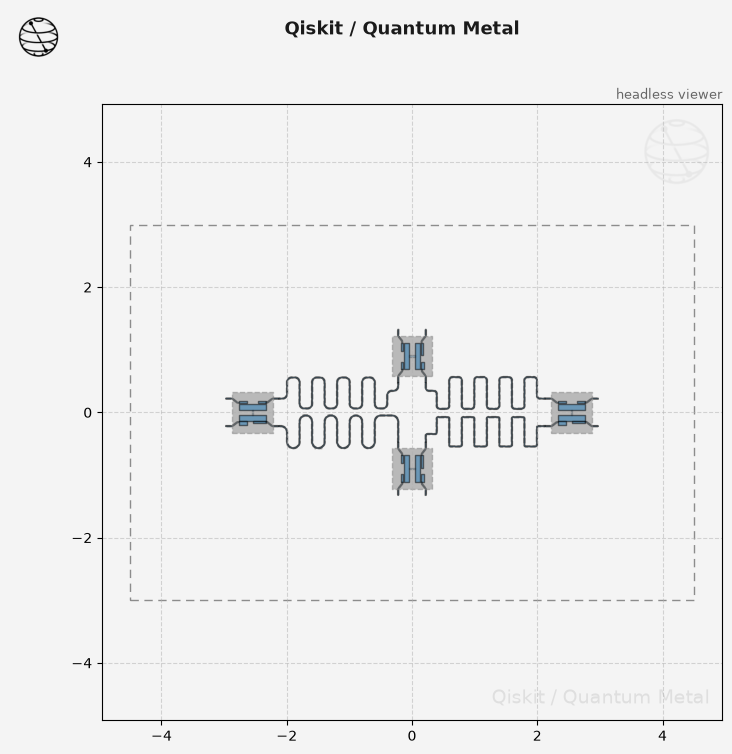

In [9]:
## Custom options for all the transmons
options = dict(
    pad_width="425 um",
    pad_gap="80 um",
    pocket_height="650um",
    # Adding 4 connectors (see below for defaults)
    connection_pads=dict(
        a=dict(loc_W=+1, loc_H=+1),
        b=dict(loc_W=-1, loc_H=+1, pad_height="30um"),
        c=dict(loc_W=+1, loc_H=-1, pad_width="200um"),
        d=dict(loc_W=-1, loc_H=-1, pad_height="50um"),
    ),
)

## Create 4 TransmonPockets
q1 = TransmonPocket(
    design,
    "Q1",
    options=dict(
        pos_x="+2.55mm", pos_y="+0.0mm", gds_cell_name="FakeJunction_02", **options
    ),
)
q2 = TransmonPocket(
    design,
    "Q2",
    options=dict(
        pos_x="+0.0mm",
        pos_y="-0.9mm",
        orientation="90",
        gds_cell_name="FakeJunction_02",
        **options,
    ),
)
q3 = TransmonPocket(
    design,
    "Q3",
    options=dict(
        pos_x="-2.55mm", pos_y="+0.0mm", gds_cell_name="FakeJunction_01", **options
    ),
)
q4 = TransmonPocket(
    design,
    "Q4",
    options=dict(
        pos_x="+0.0mm",
        pos_y="+0.9mm",
        orientation="90",
        gds_cell_name="my_other_junction",
        **options,
    ),
)

options = Dict(meander=Dict(lead_start="0.1mm", lead_end="0.1mm", asymmetry="0 um"))


def connect(
    component_name: str,
    component1: str,
    pin1: str,
    component2: str,
    pin2: str,
    length: str,
    asymmetry="0 um",
    flip=False,
    fillet="50um",
):
    """Connect two pins with a CPW."""
    myoptions = Dict(
        fillet=fillet,
        pin_inputs=Dict(
            start_pin=Dict(component=component1, pin=pin1),
            end_pin=Dict(component=component2, pin=pin2),
        ),
        lead=Dict(start_straight="0.13mm", end_straight="0.13mm"),
        total_length=length,
    )
    myoptions.update(options)
    myoptions.meander.asymmetry = asymmetry
    myoptions.meander.lead_direction_inverted = "true" if flip else "false"
    return RouteMeander(design, component_name, myoptions)


asym = 90
cpw1 = connect("cpw1", "Q1", "d", "Q2", "c", "5.7 mm", f"+{asym}um", fillet="25um")
cpw2 = connect(
    "cpw2", "Q3", "c", "Q2", "a", "5.6 mm", f"-{asym}um", flip=True, fillet="100um"
)
cpw3 = connect("cpw3", "Q3", "a", "Q4", "b", "5.5 mm", f"+{asym}um", fillet="75um")
cpw4 = connect("cpw4", "Q1", "b", "Q4", "d", "5.8 mm", f"-{asym}um", flip=True)

gui.rebuild()
gui.autoscale()

### Export list of the design QGeometries to file using your custom QSkeletonRenderer
The QSkeletonRenderer class contains several sample methods. Let's use one intended to print out the name of the QGeometry tables to a text file (Remember: QGeometry contains the list of the raw layout shapes that compose the design, which we have created in the previous cell).

In [10]:
a_skeleton.write_qgeometry_table_names_to_file("./simple_output.txt")

1

Here another example where we sub select a single QComponent instance (`cpw1`) of type RouteMeander.  This will only export the name of tables containing shapes related to that instance, which in this case is only paths, and not junctions or poly.

In [11]:
a_skeleton.write_qgeometry_table_names_to_file(
    "./simple_output_cpw1.txt", highlight_qcomponents=["cpw1"]
)

1

## What if my new tool requires additional parameters that Qiskit Metal does not natively support?

### QRenderers can request special tool parameters from the user

External tools, such as Ansys, might require special parameters to be able to render (interpret) correctly the QGeometries that Qiskit Metal wants to pass (render) to them.  Every tool might need a different set of special parameters; thus we architected a solution that allows individual QRenderers to communicate to qiskit-metal what additional parameters their associated tool requires.

The implementation consists of enabling the QRenderers to add new columns (parameters) and tables (geometry types) to the QGeometry table collection.  The QRenderer should also specify what is the default value to use to populate those columns/tables.  The user can then update them to a value different than default by editing them at run-time, which can happen through the QComponent options (or directly, for advanced users).  Note that older QComponents remain valid also for newer QRenderers, thanks to the defaults provided by the QRenderer.

Our QSkeletonRenderer class for example is designed to add a `a_column_name` column to the `junction` table, with default value `a_default_value`. This is implemented by creating the following class parameter: 
<br>`element_table_data = dict(junction=dict(a_column_name='a_default_value'))` 

Note that the final column name will be `skeleton_a_column_name` because the provided column name is prefixed with the renderer name (`QSkeletonRenderer.name`).

The method that executes the magic described above is `QRenderer.load()`, which is called from the `QSkeletonRenderer.__init__()`.

### Let's observe and update the additional properties that our QSkeletonRenderer needs
First, make sure that the registration of the QRenderer added the additional parameter as expected. Search for the column `skeleton_a_column_name` in the qgeometry table `junction`

In [12]:
design.qgeometry.tables["junction"]

,component,name,geometry,layer,subtract,helper,chip,width,gds_cell_name,skeleton_a_column_name
0,1,rect_jj,"LINESTRING (2.55 -0.04, 2.55 0.04)",1,False,False,main,0.02,FakeJunction_02,a_default_value
1,2,rect_jj,"LINESTRING (0.04 -0.9, -0.04 -0.9)",1,False,False,main,0.02,FakeJunction_02,a_default_value
2,3,rect_jj,"LINESTRING (-2.55 -0.04, -2.55 0.04)",1,False,False,main,0.02,FakeJunction_01,a_default_value
3,4,rect_jj,"LINESTRING (0.04 0.9, -0.04 0.9)",1,False,False,main,0.02,my_other_junction,a_default_value


If you cannot locate the new column (might need to scroll to the far right), then something must be amiss, so please start over this notebook and execute all of the cells.

Once you can locate the new column, and observe the set default value, let's now try to update the value in the column by modifying the design of the correspondent QComponent.  All we need to do is pass a different set of options to the component, like so:

In [13]:
q1.options.skeleton_a_column_name = "q1 skeleton"
q2.options.skeleton_a_column_name = "q2 skeleton"
q3.options.skeleton_a_column_name = "q3 skeleton"
q4.options.skeleton_a_column_name = "q4 skeleton"

gui.rebuild()  # Headless: qm.view(design)
gui.autoscale()  # Headless: omit — autoscale is GUI-only

design.qgeometry.tables["junction"]

,component,name,geometry,layer,subtract,helper,chip,width,gds_cell_name,skeleton_a_column_name
0,1,rect_jj,"LINESTRING (2.55 -0.04, 2.55 0.04)",1,False,False,main,0.02,FakeJunction_02,q1 skeleton
1,2,rect_jj,"LINESTRING (0.04 -0.9, -0.04 -0.9)",1,False,False,main,0.02,FakeJunction_02,q2 skeleton
2,3,rect_jj,"LINESTRING (-2.55 -0.04, -2.55 0.04)",1,False,False,main,0.02,FakeJunction_01,q3 skeleton
3,4,rect_jj,"LINESTRING (0.04 0.9, -0.04 0.9)",1,False,False,main,0.02,my_other_junction,q4 skeleton


You can also create the components by directly passing the options you know the renderer will require, like so:

In [14]:
q1.delete()
q2.delete()
q3.delete()
q4.delete()

q1 = TransmonPocket(
    design,
    "Q1",
    options=dict(
        pos_x="+2.55mm",
        pos_y="+0.0mm",
        gds_cell_name="FakeJunction_02",
        skeleton_a_column_name="q1 skeleton 2",
        **options,
    ),
)
q2 = TransmonPocket(
    design,
    "Q2",
    options=dict(
        pos_x="+0.0mm",
        pos_y="-0.9mm",
        orientation="90",
        gds_cell_name="FakeJunction_02",
        skeleton_a_column_name="q2 skeleton 2",
        **options,
    ),
)
q3 = TransmonPocket(
    design,
    "Q3",
    options=dict(
        pos_x="-2.55mm",
        pos_y="+0.0mm",
        gds_cell_name="FakeJunction_01",
        skeleton_a_column_name="q3 skeleton 2",
        **options,
    ),
)
q4 = TransmonPocket(
    design,
    "Q4",
    options=dict(
        pos_x="+0.0mm",
        pos_y="+0.9mm",
        orientation="90",
        gds_cell_name="my_other_junction",
        skeleton_a_column_name="q4 skeleton 2",
        **options,
    ),
)

design.qgeometry.tables["junction"]

,component,name,geometry,layer,subtract,helper,chip,width,gds_cell_name,skeleton_a_column_name
0,9,rect_jj,"LINESTRING (2.55 -0.015, 2.55 0.015)",1,False,False,main,0.02,FakeJunction_02,q1 skeleton 2
1,10,rect_jj,"LINESTRING (0.015 -0.9, -0.015 -0.9)",1,False,False,main,0.02,FakeJunction_02,q2 skeleton 2
2,11,rect_jj,"LINESTRING (-2.55 -0.015, -2.55 0.015)",1,False,False,main,0.02,FakeJunction_01,q3 skeleton 2
3,12,rect_jj,"LINESTRING (0.015 0.9, -0.015 0.9)",1,False,False,main,0.02,my_other_junction,q4 skeleton 2


## Can my user-defined renderer change/interact with the design?
### Accessing information and methods
It is possible that the result of a rendering action, or analysis requires a design update back to qiskit-metal.  This can be achieved without the user intervention by simply controlling the QDesign instance from within the QRenderer.

Just as an example, the next three cells inspect the current design QComponent, QGeometry table, and QRenderer names.

In [15]:
a_skeleton.design.components.keys()

['cpw1', 'cpw2', 'cpw3', 'cpw4', 'Q1', 'Q2', 'Q3', 'Q4']

In [16]:
a_skeleton.design.qgeometry.tables.keys()

dict_keys(['path', 'poly', 'junction'])

In [17]:
a_skeleton.design.renderers.keys()

dict_keys(['gds', 'gmsh', 'elmer', 'skeleton'])

The base QRenderer class comes with useful methods to more easily access some of the information. You will find more method described in the QRenderer documentation. The example below for example returns the QComponent's IDs.

In [18]:
a_skeleton.get_unique_component_ids(
    highlight_qcomponents=["Q1", "Q1", "Q4", "cpw1", "cpw2", "cpw3", "cpw4"]
)

([12, 6, 9, 5, 8, 7], 0)

The following instead shows three ways to access the same QGeometry table.

In [19]:
a_skeleton.design.components["Q1"].qgeometry_table("junction")  # via QComonent name
a_skeleton.design._components[9].qgeometry_table("junction")  # via QComponent ID
q1.qgeometry_table("junction")  # via the QComponent instance

,component,name,geometry,layer,subtract,helper,chip,width,gds_cell_name,skeleton_a_column_name
0,9,rect_jj,"LINESTRING (2.55 -0.015, 2.55 0.015)",1,False,False,main,0.02,FakeJunction_02,q1 skeleton 2


The method `QSkeletonRenderer.get_qgeometry_tables_for_skeleton()` exemplifies how to iterate through chips and tables.

In [20]:
from skeleton_renderer import QSkeletonRenderer  # importable after the registration cell

# The '?' IPython magic displays the docstring for the method inline.
# Non-IPython equivalent: help(QSkeletonRenderer.get_qgeometry_tables_for_skeleton)
?QSkeletonRenderer.get_qgeometry_tables_for_skeleton

### Communicate state
We can also interact with any other method of the QDesign instance, for example we can generate a warning into the logger as shown in the next cell.  This is particularly useful to document problems with the user defined QRenderer execution

In [21]:
# Purposefully generates a warning message.
a_skeleton.logger.warning("Show a warning message for plugin developer.")

04:13PM 49s WARNING [<module>]: Show a warning message for plugin developer.


## Qiskit Metal Version

In [22]:
metal.about();


Qiskit Metal        0.9.0

Basic
____________________________________
 Python              3.12.15 | packaged by Anaconda, Inc. | (main, Oct  1 2026, 20:20:25) [GCC 14.3.0]
 Platform            Linux x86_64

Packages
____________________________________
 Numpy               2.5.3
 Qutip               5.3.1

Rendering
____________________________________
 Matplotlib          3.11.2

GUI
____________________________________
 PySide6 version     Not installed
 Qt version          Not installed
 SIP version         Not installed

IBM Quantum Team


In [23]:
# Uncomment to close the GUI window when done:
# gui.main_window.close()